# Visualising data with Seaborn

[Seaborn](http://seaborn.pydata.org/).

This week is about turning a research question into a clear graph. We will use a few useful graph types. Bar graphs, scatter plots, line plots.


Seaborn is an amazing tool that defines simple high-level functions for common statistical plot types, and integrates with the functionality provided by Pandas DataFrames.

For more information on plotting with Seaborn, see the [Seaborn documentation](http://seaborn.pydata.org/), a [tutorial](http://seaborn.pydata.org/
tutorial.htm), and the [Seaborn gallery](http://seaborn.pydata.org/examples/index.html).

## Setup

Seaborn makes graphs from pandas DataFrames. Matplotlib gives us control over the figure, labels and scales.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [ ]:
# These files were introduced in Week 3.
scotland_names_df = pd.read_csv("../week_3/scotland_babynames.csv")
usa_names_df = pd.read_csv("../week_3/us_babynames_by_region.csv")

display(scotland_names_df.head())
display(usa_names_df.head())

The `_df` ending is a useful label for us: it reminds us that these variables contain whole DataFrames.

Before plotting, say what one row represents. In the Scottish table, one row is one name, for one sex, in one year. In the US table, one row also belongs to one region.

## Bar charts compare categories

**Question:** What were the ten most common girls' names registered in Scotland in 2025?

First make the small table that the graph will display. A graph is not a substitute for preparing the right data.

In [ ]:
select_2025 = scotland_names_df["Year"] == 2025
select_girls = scotland_names_df["Sex"] == "F"

girls_2025_df = scotland_names_df.loc[
    select_2025 & select_girls,
    ["Name", "Count"],
]

top_10_girls_df = girls_2025_df.sort_values("Count", ascending=False).head(10)
top_10_girls_df

## How Seaborn builds a graph

Seaborn makes graphs directly from a pandas DataFrame. We tell it **which table to use** and **which job each column should perform**:

```python
sns.PLOTTYPE(
    data=df,
    x="column_name",
    y="column_name",
    hue="column_name",
)
```


- `data=` specifies the DataFrame containing the data.
- `x=` selects the column placed along the horizontal axis.
- `y=` selects the column placed along the vertical axis.
- `hue=` uses another column to separate groups by colour.

A useful way to read this code aloud is:

The column names are written as strings because Seaborn looks for columns with those names inside the DataFrame supplied to `data=`.


Quick note what I wrote above python considers -identical- to this: 

```python
sns.PLOTTYPE( data=df, x="column_name", y="column_name", hue="column_name", )
```


It's a function call with multiple inputs.   I put each input on a separate line so the they are easier to read and change.  

# Seaborn bar graph

Next we'll turn a table into a dataframe.  

In [ ]:
# this line initializses a figure.   it is a good idea to do this before plotting, 
# so that you can control the size of the figure, and have a convienient 
# reference to the figure and axes objects that can be used to customize the plot.
fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=top_10_girls_df,
    x="Count",
    y="Name",
    color="#6A5ACD",
    ax=ax,
)


# #Here we are using the axes object "ax" to set the title and labels for the plot. 
# ax.set_title("Ten most common girls' names in Scotland, 2025")
# ax.set_xlabel("Number of babies")
# ax.set_ylabel("Name")
# ax.set_xlim(left=0)

plt.show()

`fig` is the whole picture. `ax` is the plotting area—the part with the axes, labels and data. We pass `ax=ax` to Seaborn, then use the same object to improve the graph.

A horizontal bar chart leaves room for the names. The bars start at zero because their lengths represent amounts.

### Live coding pause: extend the question

Change the selections to show boys' names, or choose another year. Before running the graph, predict one thing that might change.

## Scatter plots show the relationship between two numeric variables

**Question:** In the 2025 Scottish data, Does the length of a name relate to a babies gender?

We need to derive a new numeric column. The string method `.str.len()` counts the characters in every name.

In [ ]:
names_2025_df = scotland_names_df.loc[select_2025].copy()
names_2025_df["NameLength"] = names_2025_df["Name"].str.len()

names_2025_df[["Sex", "Name", "NameLength", "Count"]].head()

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(
    data=names_2025_df,
    x="NameLength",
    y="Count",
    hue="Sex",
    alpha=0.55,
    ax=ax,
)

ax.set_title("Name length and popularity in Scotland, 2025")
ax.set_xlabel("Number of characters in the name")
ax.set_ylabel("Number of babies")
ax.legend(title="Sex recorded at registration")

plt.show()

Each point is one name. `hue` gives a categorical variable the job of controlling colour. Transparency helps us see where points overlap.

This isn't very good way to look at this data.  Every different name is a different dot! But we didn't care about different names, we grouped them together.   

### Not every plot is a useful way to investigate the data

This plot didn't do a great job addressing that question.    We can come back to that. 

## Counts are not always comparable

Suppose 1,000 girls are represented in one place and 10,000 in another. A count of 50 has a very different meaning in those two populations.  Population has grown a lot over the last 100 years so it's usefule to consider the percentage of babies given a name, not just the count.   

But instead of per 100 (like percent) I'm going to do it as  popularity **per 1,000 recorded names**.   It's the same concept with different unit.   


This is the same general idea as calculating cases per 100,000 in the assignment.

In [ ]:

scotland_total_df = (
    scotland_names_df.groupby(["Year", "Sex"], as_index=False)["Count"]
    .sum()
)

#Let's rename that column to "TotalCount" so that we can merge it with the original dataframe later.
scotland_total_df.rename(columns={"Count": "TotalCount"}, inplace=True)

sns.lineplot(data=scotland_total_df, x="Year", y="TotalCount", hue="Sex", estimator=None)

Once we have calculated those we can merge them back into the main dataframe. 

In [ ]:
#Merge the total counts back in.  Note that the merge is needed because
#the grouped counts collapsed all the names for each year and sex into a single row, so we need to merge it back to the original dataframe to have the total counts available for each name.
scotland_names_df= pd.merge(scotland_names_df, scotland_total_df, on=["Year", "Sex"],how="left")


In [ ]:
scotland_names_df["CountPer1000"] = 1000 * (scotland_names_df["Count"] / scotland_names_df["TotalCount"])
scotland_names_df

In [ ]:
#Let's check George. 
select_name = scotland_names_df["Name"] == "George"

sns.lineplot(
    data=scotland_names_df[select_name],
    x="Year",
    y="Count"
)


##

### Now let's do this for the USA

In [ ]:

#Calculate the totals for year, region, sex seperately. 
totals_by_region_df = (
    usa_names_df
    .groupby(["Year", "Region", "Sex"], as_index=False)["Count"]
    .sum()
    .rename(columns={"Count": "TotalNamesByGender"})
)

#Merge the totals back in. 
usa_names_df = pd.merge(
    usa_names_df,
    totals_by_region_df,
    on=["Year", "Region", "Sex"],
)

#Now add in the CountPer1000 column to the usa_names_df dataframe.
usa_names_df["CountPer1000"] = 1000 * (usa_names_df["Count"] / usa_names_df["TotalNamesByGender"])
usa_names_df.head()


The work happens in visible stages:

- `groupby()` calculates the relevant denominator for every year and region and sex.
- `merge()` attaches the correct denominator to each count.
- The formula creates the comparable measure.

Always inspect the prepared table before trusting the graph.

### Now let's look at the popularity over time for a spec

In [ ]:
select_hillary = usa_names_df["Name"] == "Hillary"

#Here's a new way to make a slection. 
select_years =  hillary_df["Year"].between(1988, 1996)

#Notice the boolean & takin gboth Hillary and the years. 
usa_names_df.loc[select_hillary & select_years, :].head(10)

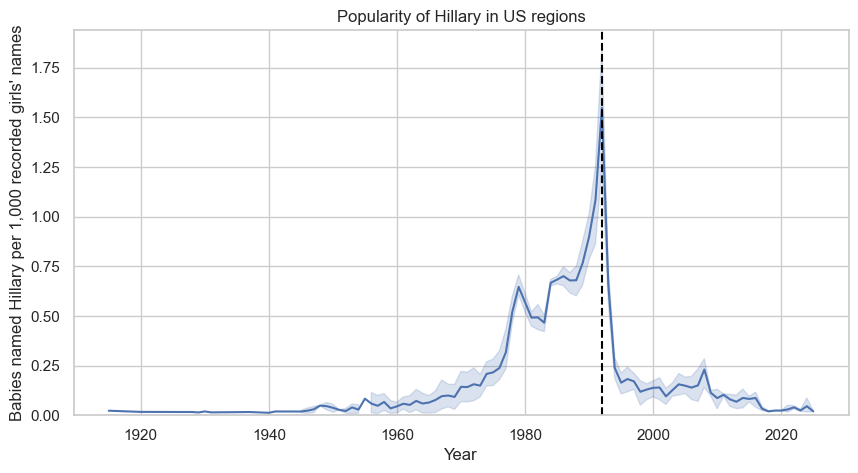

In [120]:
# hillary_recent_df = hillary_df.loc[hillary_df["Year"] >= 1960]

fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=usa_names_df.loc[select_hillary], #<--- We can pass in a subset of a dataframe.
    x="Year",
    y="CountPer1000",
    ax=ax,
)

ax.axvline(1992, color="black", linestyle="--", label="1992 election")
ax.set_title("Popularity of Hillary in US regions")
ax.set_xlabel("Year")
ax.set_ylabel("Babies named Hillary per 1,000 recorded girls' names")
ax.set_ylim(bottom=0)
# ax.legend(title="Region / event")

plt.show()

The name peaks in 1992 and falls sharply afterwards in every region. The timing is interesting and worth discussing, but the graph alone does not prove that the election caused the change.

Note about the error bars.   Seaborn nicely often adds in errorbars for for you.  In this case we have multiple regions and it calculates the variability for you. 

Note: Check counts versus comparable rates

Change `y="Per1000"` to `y="Count"`. Which regional differences become larger? Why might population size be influencing that graph?

## Now lets return to the name lengths

We should calculate the totals ourselves.  

In [ ]:

#Calculate the total for the count. 


# calcaulte the total for count, and keep the name length and sex columns.  This will give us a dataframe with the total counts for each name length and sex combination.
names_total_by_length_2025_df = names_2025_df.groupby(["NameLength", "Sex"], as_index=False)["Count"].sum()

names_total_by_length_2025_df



In [ ]:
sns.barplot(
    data=names_total_by_length_2025_df,
    x="NameLength",
    y="Count",
    hue="Sex",

)




## Questions to ask about the graph

- What does one point, bar or line represent?
- Are the title, labels, units and legend understandable and legible?
- Does the graph answer the stated question?
- If two graphs are compared, are their scales comparable?
- Does a quick data audit table agree with the graph?
- Are colors/labels used consistently?
